In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from typing import Tuple, Dict

### Objective function and analytic gradient

We will use a **two-dimensional non-convex test function**, formed by combining a quadratic bowl with two Gaussian wells. The function is defined as:

$$
f(x,y)= -2\,\exp\!\left(-\tfrac{(x-1)^2+y^2}{0.2}\right)
        -3\,\exp\!\left(-\tfrac{(x+1)^2+y^2}{0.2}\right)
        + x^2+y^2 .
$$

This creates two Gaussian “wells” centered at $(1,0)$ and $(-1,0)$ (the left one being deeper), plus a quadratic bowl centered at the origin.

Let

$$
e_1=\exp\!\left(-\tfrac{(x-1)^2+y^2}{0.2}\right), \qquad
e_2=\exp\!\left(-\tfrac{(x+1)^2+y^2}{0.2}\right).
$$

The gradient is:

$$
\nabla f(x,y)=
\begin{bmatrix}
2x + 20(x-1)\,e_1 + 30(x+1)\,e_2 \\[4pt]
2y + 20y\,e_1 + 30y\,e_2
\end{bmatrix}.
$$

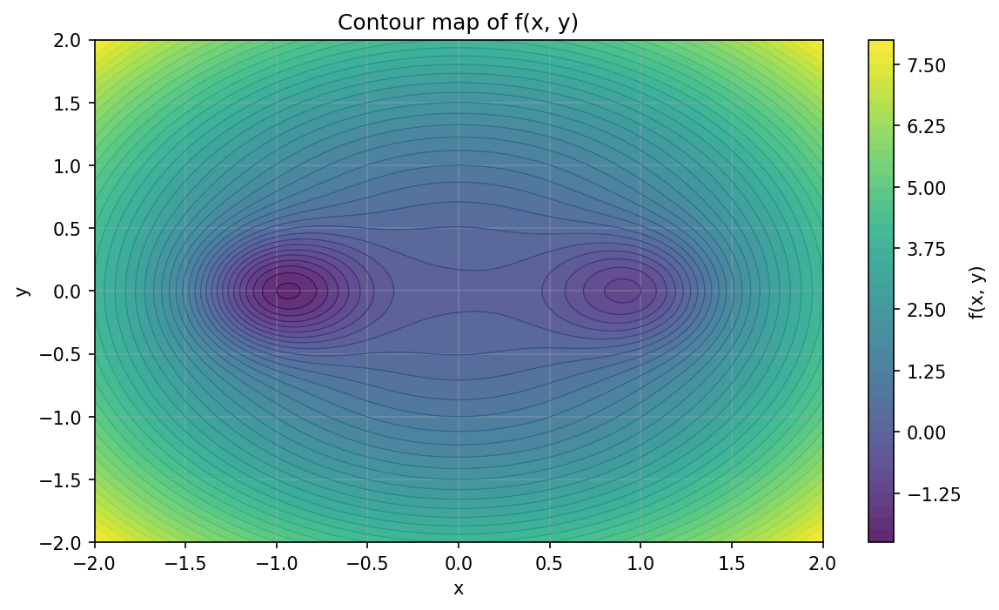

In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------
# Define objective function f(x,y)
# -------------------------------------
def f(x: float, y: float) -> float:
    """
    Objective: quadratic bowl + two Gaussian wells.
    """
    # fill in the exponential terms e1 and e2
    e1 = math.exp(-((x - 1)**2 + y**2) / 0.2) # well centered at (1,0)
    e2 = math.exp(-((x + 1)**2 + y**2) / 0.2) # well centered at (-1,0)

    return -2.0 * e1 - 3.0 * e2 + x * x + y * y


# Gradient ∇f(x,y)
# -------------------------------------
def grad(x: float, y: float) -> np.ndarray:
    """
    Analytic gradient of f(x,y).
    """
    # fill in the exponential terms e1 and e2
    e1 = math.exp(-(((x-1)**2)+y**2)/0.2) # well centered at (1,0)
    e2 = math.exp(-(((x+1)**2) + y**2)/0.2) # well centered at (-1,0)


    # fill in gx = ∂f/∂x, gy = ∂f/∂y
    gx = 2*x + 20*(x - 1)*e1 + 30*(x + 1)*e2
    gy = 2*y + 20*y*e1 + 30*y*e2

    return np.array([gx, gy], dtype=float)


# -------------------------------------
# Plot contour of f(x,y)
# -------------------------------------
xlim = (-2.0, 2.0)
ylim = (-2.0, 2.0)
res  = 400

xs = np.linspace(*xlim, res)
ys = np.linspace(*ylim, res)
XX, YY = np.meshgrid(xs, ys)

ZZ = np.vectorize(f)(XX, YY)

fig, ax = plt.subplots(figsize=(9, 5), dpi=150)

cf = ax.contourf(XX, YY, ZZ, levels=40, alpha=0.85)
ax.contour(XX, YY, ZZ, levels=40, linewidths=0.6)

fig.colorbar(cf, ax=ax, label='f(x, y)')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Contour map of f(x, y)')
ax.set_xlim(xlim)
ax.set_ylim(ylim)
ax.grid(True, alpha=0.3)

plt.show()


### Optimizers

We will implement and compare several optimization algorithms. Each algorithm updates the parameters
$(x_t, y_t)$ using the gradient $\nabla f(x_t, y_t)$.

---

#### 1. Gradient Descent (GD)

The simplest method performs a step in the **negative gradient direction**:

$$
(x_{t+1}, y_{t+1}) = (x_t, y_t) - \eta \,\nabla f(x_t, y_t),
$$

where $\eta > 0$ is the learning rate.

---

#### 2. Momentum

Momentum introduces a velocity vector $v_t$ that accumulates past gradients:

$$
\begin{aligned}
v_{t+1} &= \mu v_t - \eta \nabla f(x_t, y_t), \\
(x_{t+1}, y_{t+1}) &= (x_t, y_t) + v_{t+1},
\end{aligned}
$$

where $0 \le \mu < 1$ is the momentum parameter.

---

#### 3. Signed Gradient Descent (SignGD)

Instead of using the gradient magnitude, we only use the **sign** of each component:

$$
(x_{t+1}, y_{t+1}) = (x_t, y_t) - \eta \,\mathrm{sign}\!\left(\nabla f(x_t, y_t)\right).
$$

This results in uniform-sized steps in each coordinate direction.

---

#### 4. Soft-Signed Gradient Descent

To smooth the discontinuity of the sign function, we apply a **softsign** transform with parameter $\tau > 0$:

$$
\mathrm{softsign}(z) = \frac{z/\tau}{1 + |z|/\tau}.
$$

The update becomes

$$
(x_{t+1}, y_{t+1}) = (x_t, y_t) - \eta \,\mathrm{softsign}\!\Big(\nabla f(x_t, y_t)\Big).
$$

---

#### 5. RMSProp

RMSProp normalizes the gradient by a running average of its squared values:

$$
\begin{aligned}
v_{t+1} &= \beta v_t + (1-\beta)\,\big(\nabla f(x_t, y_t)\big)^{\odot 2}, \\
(x_{t+1}, y_{t+1}) &= (x_t, y_t) - \eta \,\frac{\nabla f(x_t, y_t)}{\sqrt{v_{t+1}} + \varepsilon},
\end{aligned}
$$

where $\odot$ denotes elementwise square.

---

#### 6. Adam

Adam combines **momentum** and **adaptive scaling** (like RMSProp). It maintains first- and second-moment estimates:

$$
\begin{aligned}
m_{t+1} &= \beta_1 m_t + (1-\beta_1)\,\nabla f(x_t, y_t), \\
v_{t+1} &= \beta_2 v_t + (1-\beta_2)\,\big(\nabla f(x_t, y_t)\big)^{\odot 2}, \\
\hat m_{t+1} &= \frac{m_{t+1}}{1-\beta_1^{t+1}}, \quad
\hat v_{t+1} = \frac{v_{t+1}}{1-\beta_2^{t+1}}, \\
(x_{t+1}, y_{t+1}) &= (x_t, y_t) - \eta \,\frac{\hat m_{t+1}}{\sqrt{\hat v_{t+1}}+\varepsilon}.
\end{aligned}
$$



In [3]:
# -----------------------------
# Optimizers (fill in the TODO parts)
# -----------------------------

def run_gd(x0: float, y0: float, steps: int, lr: float):
    x, y = x0, y0
    traj = [(x, y)]
    losses = [f(x, y)]
    for _ in range(steps):
        g = grad(x, y)
        # update x, y using gradient descent
        # x = ...
        x = x - lr * g[0]
        # y = ...
        y = y - lr * g[1]
        traj.append((x, y))
        losses.append(f(x, y))
    return np.array(traj), np.array(losses)


def run_momentum(x0: float, y0: float, steps: int, lr: float, mu: float = 0.9):
    x, y = x0, y0
    v = np.zeros(2)   # velocity
    traj = [(x, y)]
    losses = [f(x, y)]
    for _ in range(steps):
        g = grad(x, y)
        # update velocity v and parameters x, y
        # v = ...
        v = mu * v - lr * g
        # x = ...
        x = x + v[0]
        # y = ...
        y = y + v[1]

        traj.append((x, y))
        losses.append(f(x, y))
    return np.array(traj), np.array(losses)


def run_sign_gd(x0: float, y0: float, steps: int, lr: float):
    """Elementwise sign(grad) step (a.k.a. signSGD)."""
    x, y = x0, y0
    traj = [(x, y)]
    losses = [f(x, y)]
    for _ in range(steps):
        g = grad(x, y)
        # update x, y using only the sign of g
        # step = ...
        step = np.sign(g)
        # x = ...
        x = x - lr * step[0]
        # y = ...
        y = y - lr * step[1]

        traj.append((x, y))
        losses.append(f(x, y))
    return np.array(traj), np.array(losses)


def run_softsign_gd(x0: float, y0: float, steps: int, lr: float, tau: float = 5.0):
    """
    Soft-signed step: elementwise softsign(g/tau) = (g/tau) / (1 + |g|/tau).
    Saturates like sign but remains smooth around 0.
    """
    x, y = x0, y0
    traj = [(x, y)]
    losses = [f(x, y)]
    for _ in range(steps):
        g = grad(x, y)
        # compute softsign of g, then update x, y
        # z = ...
        z = g / tau
        # soft = ...
        soft = z / (1 + np.abs(g)/tau)
        # step = ...
        step = lr * soft
        # x = ...
        x = x - step[0]
        # y = ...
        y = y - step[1]

        traj.append((x, y))
        losses.append(f(x, y))
    return np.array(traj), np.array(losses)


def run_rmsprop(x0: float, y0: float, steps: int, lr: float, beta: float = 0.99, eps: float = 1e-8):
    x, y = x0, y0
    v = np.zeros(2)  # running average of squared gradients
    traj = [(x, y)]
    losses = [f(x, y)]
    for _ in range(steps):
        g = grad(x, y)
        # update running average v and parameters x, y
        # v = ...
        v = beta * v + (1 - beta) * g**2
        # step = ...
        step = lr * g / (np.sqrt(v) + eps)
        # x = ...
        x = x - step[0]
        # y = ...
        y = y - step[1]
        traj.append((x, y))
        losses.append(f(x, y))
    return np.array(traj), np.array(losses)


def run_adam(x0: float, y0: float, steps: int, lr: float, b1: float = 0.9, b2: float = 0.999, eps: float = 1e-8):
    x, y = x0, y0
    m = np.zeros(2)  # first moment (mean of gradients)
    v = np.zeros(2)  # second moment (mean of squared gradients)
    traj = [(x, y)]
    losses = [f(x, y)]
    for t in range(1, steps + 1):
        g = grad(x, y)
        # update m, v, compute bias-corrected mhat, vhat, then update x, y
        # m = ...
        m = b1 * m + (1 - b1) * g
        # v = ...
        v = b2 * v + (1 - b2) * g**2
        # mhat = ...
        mhat = m / (1 - b1**t)
        # vhat = ...
        vhat = v / (1 - b2**t)
        # step = ...
        step = lr * mhat / (np.sqrt(vhat) + eps)
        # x = ...
        x = x - step[0]
        # y = ...
        y = y - step[1]

        traj.append((x, y))
        losses.append(f(x, y))
    return np.array(traj), np.array(losses)


In [4]:
# -----------------------------
# Optimizers
# -----------------------------

def run_all(x0: float, y0: float, steps: int, HYPERS):
    results = {}
    results["GD"]        = run_gd(x0, y0, steps, **HYPERS["GD"])
    results["Momentum"]  = run_momentum(x0, y0, steps, **HYPERS["Momentum"])
    results["SignedGD"]  = run_sign_gd(x0, y0, steps, **HYPERS["SignedGD"])
    results["SoftSignGD"]= run_softsign_gd(x0, y0, steps, **HYPERS["SoftSignGD"])
    results["RMSProp"]   = run_rmsprop(x0, y0, steps, **HYPERS["RMSProp"])
    results["Adam"]      = run_adam(x0, y0, steps, **HYPERS["Adam"])
    return results

def draw(results: Dict[str, tuple], xlim=(-2, 2), ylim=(-2, 2)):
    xs = np.linspace(xlim[0], xlim[1], 300)
    ys = np.linspace(ylim[0], ylim[1], 300)
    XX, YY = np.meshgrid(xs, ys)
    ZZ = np.vectorize(f)(XX, YY)

    fig, ax = plt.subplots(figsize=(8, 6), dpi=300)
    cf = ax.contourf(XX, YY, ZZ, levels=30, alpha=0.8)
    ax.set_facecolor("white")
    ax.contour(XX, YY, ZZ, levels=30, linewidths=0.5)

    styles = {
        "GD": "-.",
        "Momentum": (0, (1, 1)),
        "SignGD": "-",
        "SoftSignGD": (0, (1, 1)),
        "RMSProp": (0, (3, 1, 1, 1)),
        "Adam": (0, (5, 1, 1, 1)),
    }

    # Plot each path
    for name, (traj, losses) in results.items():
        ax.plot(traj[:, 0], traj[:, 1], linestyle=styles.get(name, "-"), linewidth=2, label=name)
        ax.plot(traj[0, 0], traj[0, 1], marker="o", markersize=4)
        ax.plot(traj[-1, 0], traj[-1, 1], marker="x", markersize=6)

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title("Optimization trajectories on a 2D landscape")
    ax.legend(loc="upper left", frameon=True)

    out_path = "./optimizer_trajectories.png"
    fig.tight_layout()
    fig.savefig(out_path, dpi=300)
    plt.show()
    return out_path

def print_final_points_and_losses(results: Dict[str, tuple], start=None, steps: int | None = None):
    if steps is None:
        any_name = next(iter(results))
        steps = len(results[any_name][1]) - 1

    header = f"Final results after {steps} steps"
    if start is not None:
        header += f", start = ({start[0]:.4f}, {start[1]:.4f})"
    print(header)

    for name, (traj, losses) in results.items():
        xT, yT = traj[-1, 0], traj[-1, 1]
        fT = losses[-1]
        print(f"{name:>10s}: f(x_T) = {fT: .6f},  at (x_T, y_T) = ({xT: .4f}, {yT: .4f})")

    best_name, best_val = min(
        ((n, ls[-1]) for n, (_, ls) in results.items()),
        key=lambda kv: kv[1]
    )
    print(f"\nLowest loss for this single demonstration run: {best_name} with f(x_T) = {best_val:.6f}")

Final results after 500 steps, start = (1.2000, 1.2000)
        GD: f(x_T) = -1.092732,  at (x_T, y_T) = ( 0.9053,  0.0000)
  Momentum: f(x_T) = -2.063090,  at (x_T, y_T) = (-0.9363, -0.0000)
  SignedGD: f(x_T) = -1.092459,  at (x_T, y_T) = ( 0.9000, -0.0000)
SoftSignGD: f(x_T) = -1.092732,  at (x_T, y_T) = ( 0.9053,  0.0000)
   RMSProp: f(x_T) = -1.088058,  at (x_T, y_T) = ( 0.8899,  0.0152)
      Adam: f(x_T) = -1.092661,  at (x_T, y_T) = ( 0.9069, -0.0021)

Lowest loss for this single demonstration run: Momentum with f(x_T) = -2.063090


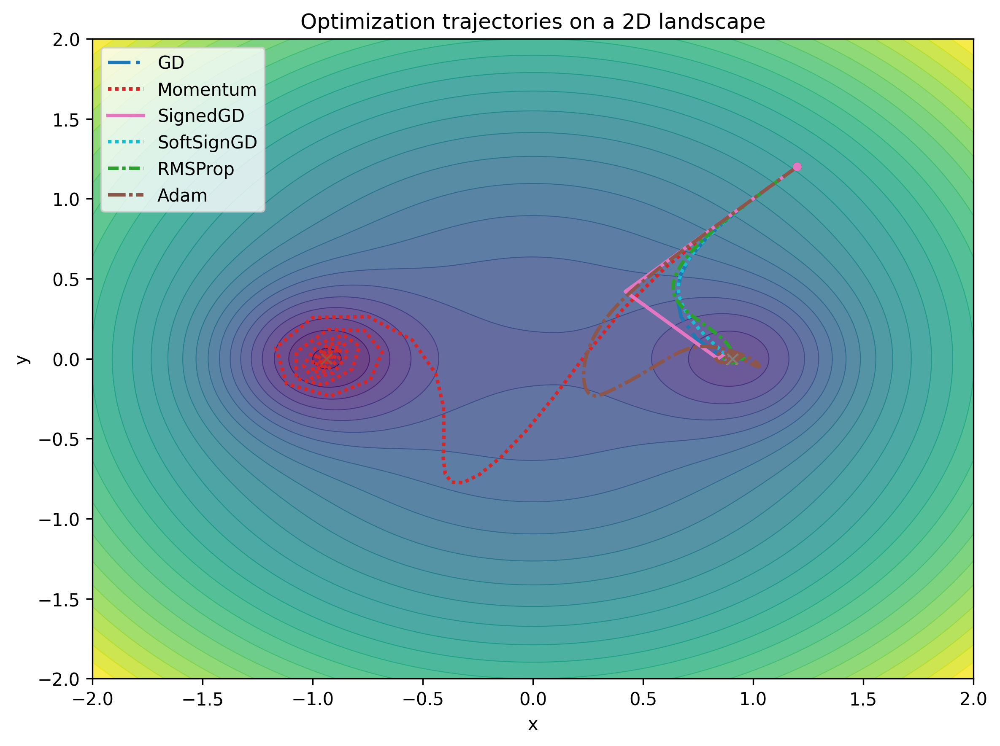

In [5]:
#START: Tuple[float, float] = (-1.2, 1.2)
START: Tuple[float, float] = (1.2, 1.2)
#START: Tuple[float, float] = (0.3, 1.5)

# STEPS = 50
# STEPS = 200
STEPS = 500

HYPERS: Dict[str, dict] = {
    "GD":        dict(lr=0.05),
    "Momentum":  dict(lr=0.03, mu=0.9),
    "SignedGD":  dict(lr=0.03),
    "SoftSignGD":dict(lr=0.10, tau=5.0),
    "RMSProp":   dict(lr=0.03, beta=0.9, eps=1e-8),
    "Adam":      dict(lr=0.05, b1=0.9, b2=0.9, eps=1e-8),
}

results_ = run_all(*START, STEPS, HYPERS)
print_final_points_and_losses(results_, start=START, steps=STEPS)
png_path = draw(results_)

## **Trajectory Visualization Across Initializations and Step Budgets**

In [6]:
# -------------------------------------
# Trajectory visualization
# -------------------------------------

STARTS = [
    (-1.2, 1.2),
    (1.2, 1.2),
    (0.3, 1.5)
]

BUDGETS = [10, 50, 200]


optimizers = {
    "GD": lambda x, y, T: run_gd(
        x, y, T, lr=0.05
    ),

    "Momentum": lambda x, y, T: run_momentum(
        x, y, T, lr=0.03, mu=0.9
    ),

    "SignedGD": lambda x, y, T: run_sign_gd(
        x, y, T, lr=0.03
    ),

    "SoftSignGD": lambda x, y, T: run_softsign_gd(
        x, y, T, lr=0.10, tau=5.0
    ),

    "RMSProp": lambda x, y, T: run_rmsprop(
        x, y, T, lr=0.03, beta=0.9
    ),

    "Adam": lambda x, y, T: run_adam(
        x, y, T, lr=0.05, b1=0.9, b2=0.9
    )
}

In [7]:
def plot_trajectory(name, traj, start, steps):

    # Create contour grid
    xs = np.linspace(-2, 2, 400)
    ys = np.linspace(-2, 2, 400)

    XX, YY = np.meshgrid(xs, ys)

    ZZ = np.vectorize(f)(XX, YY)

    # Plot contour
    plt.figure(figsize=(7, 5))

    plt.contourf(
        XX,
        YY,
        ZZ,
        levels=40,
        alpha=0.8
    )

    plt.contour(
        XX,
        YY,
        ZZ,
        levels=40,
        linewidths=0.5
    )

    # Plot optimizer trajectory
    plt.plot(
        traj[:, 0],
        traj[:, 1],
        linewidth=2,
        label=name
    )

    # Starting point
    plt.plot(
        traj[0, 0],
        traj[0, 1],
        "o",
        markersize=8,
        label="Start"
    )

    # Ending point
    plt.plot(
        traj[-1, 0],
        traj[-1, 1],
        "x",
        markersize=10,
        label="End"
    )

    plt.xlim(-2, 2)
    plt.ylim(-2, 2)

    plt.xlabel("x")
    plt.ylabel("y")

    plt.title(
        f"{name}: start={start}, T={steps}"
    )

    plt.legend()
    plt.grid(alpha=0.3)

    plt.show()

I use the numerically estimated minima near (-0.9363, 0) and (0.9053, 0) and classify a run as converged when its final point is within 0.15 of one of them.

In [8]:
LEFT_WELL = np.array([-0.9363, 0.0])
RIGHT_WELL = np.array([0.9053, 0.0])

def classify_well(x, y, tol=0.15):
    point = np.array([x, y])

    left_distance = np.linalg.norm(point - LEFT_WELL)
    right_distance = np.linalg.norm(point - RIGHT_WELL)

    if min(left_distance, right_distance) > tol:
        return "Not converged"

    if left_distance < right_distance:
        return "Left well"
    else:
        return "Right well"

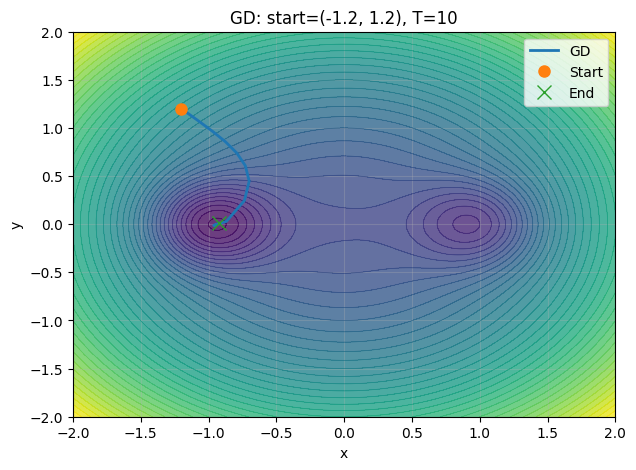

GD
Start: (-1.2, 1.2)
Steps: 10
Final point: (-0.9224, 0.0082)
Final loss: -2.059169
Final well: Left well
----------------------------------------


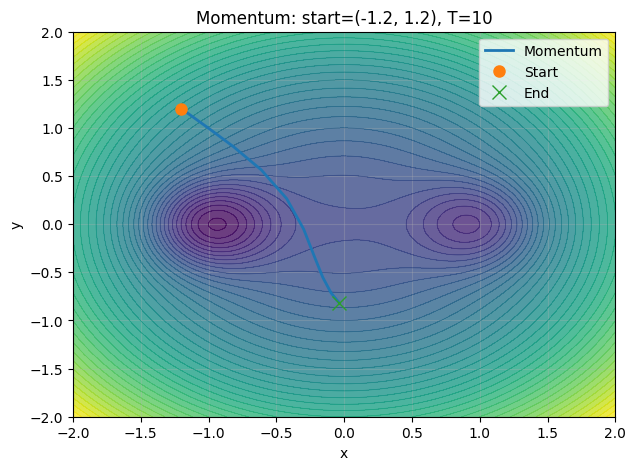

Momentum
Start: (-1.2, 1.2)
Steps: 10
Final point: (-0.0349, -0.8191)
Final loss: 0.670863
Final well: Not converged
----------------------------------------


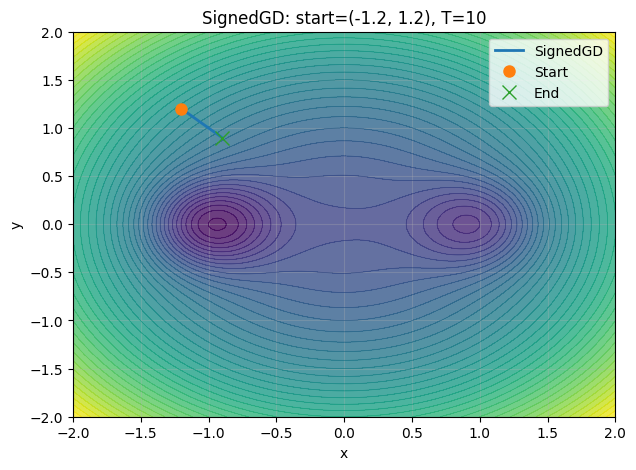

SignedGD
Start: (-1.2, 1.2)
Steps: 10
Final point: (-0.9000, 0.9000)
Final loss: 1.570282
Final well: Not converged
----------------------------------------


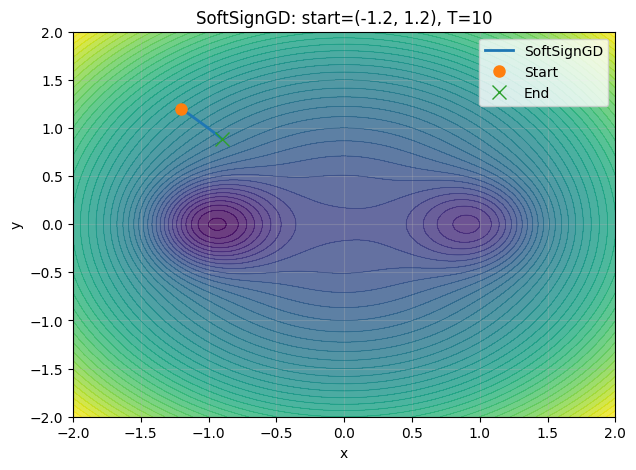

SoftSignGD
Start: (-1.2, 1.2)
Steps: 10
Final point: (-0.9026, 0.8878)
Final loss: 1.547370
Final well: Not converged
----------------------------------------


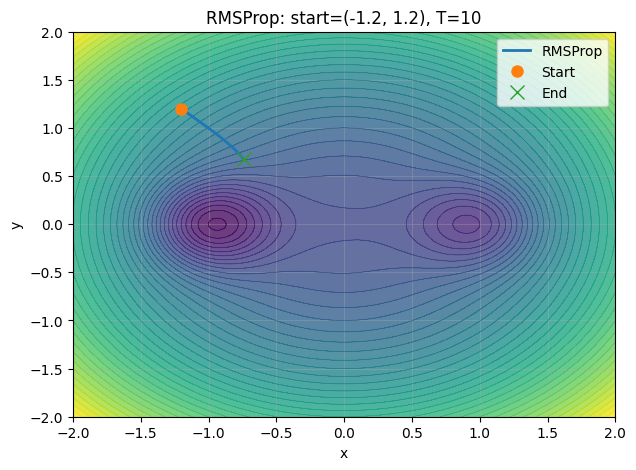

RMSProp
Start: (-1.2, 1.2)
Steps: 10
Final point: (-0.7410, 0.6753)
Final loss: 0.785725
Final well: Not converged
----------------------------------------


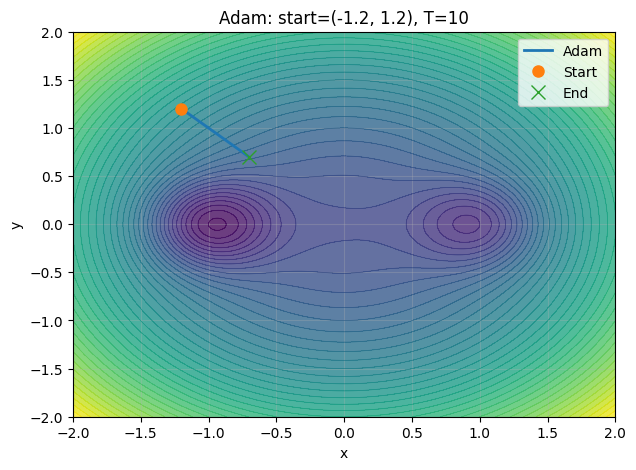

Adam
Start: (-1.2, 1.2)
Steps: 10
Final point: (-0.7029, 0.7002)
Final loss: 0.818160
Final well: Not converged
----------------------------------------


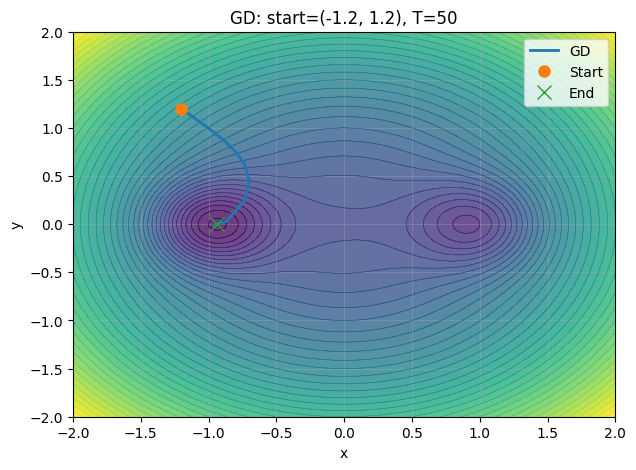

GD
Start: (-1.2, 1.2)
Steps: 50
Final point: (-0.9363, 0.0000)
Final loss: -2.063090
Final well: Left well
----------------------------------------


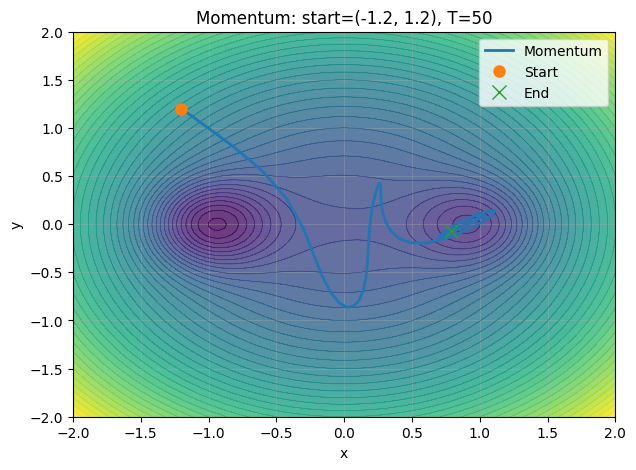

Momentum
Start: (-1.2, 1.2)
Steps: 50
Final point: (0.7864, -0.0743)
Final loss: -0.924728
Final well: Right well
----------------------------------------


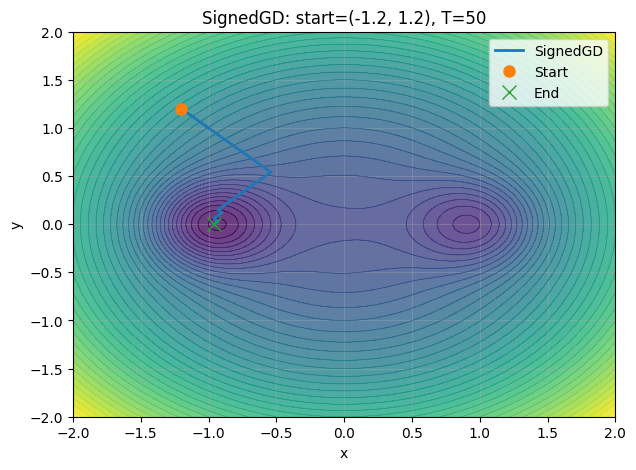

SignedGD
Start: (-1.2, 1.2)
Steps: 50
Final point: (-0.9600, -0.0000)
Final loss: -2.054496
Final well: Left well
----------------------------------------


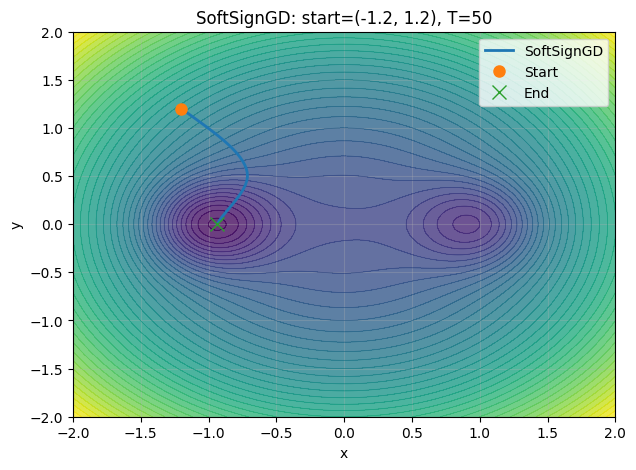

SoftSignGD
Start: (-1.2, 1.2)
Steps: 50
Final point: (-0.9363, 0.0000)
Final loss: -2.063090
Final well: Left well
----------------------------------------


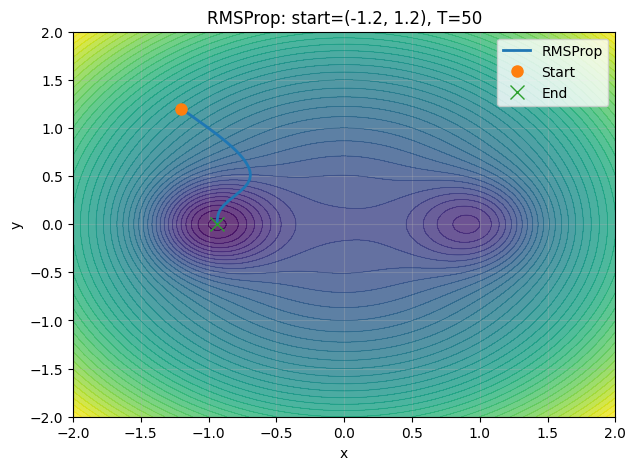

RMSProp
Start: (-1.2, 1.2)
Steps: 50
Final point: (-0.9363, 0.0000)
Final loss: -2.063090
Final well: Left well
----------------------------------------


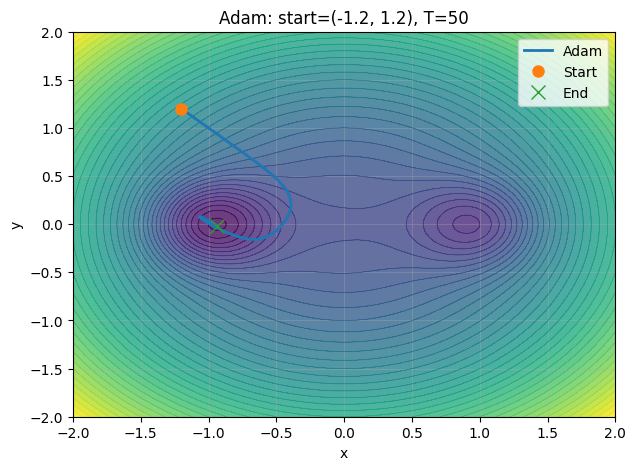

Adam
Start: (-1.2, 1.2)
Steps: 50
Final point: (-0.9383, -0.0137)
Final loss: -2.060064
Final well: Left well
----------------------------------------


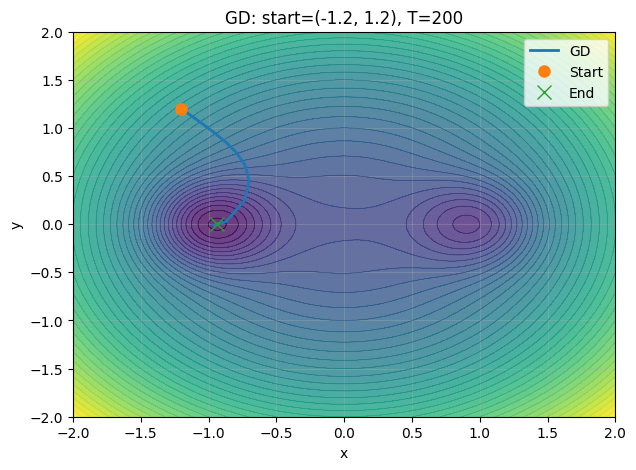

GD
Start: (-1.2, 1.2)
Steps: 200
Final point: (-0.9363, 0.0000)
Final loss: -2.063090
Final well: Left well
----------------------------------------


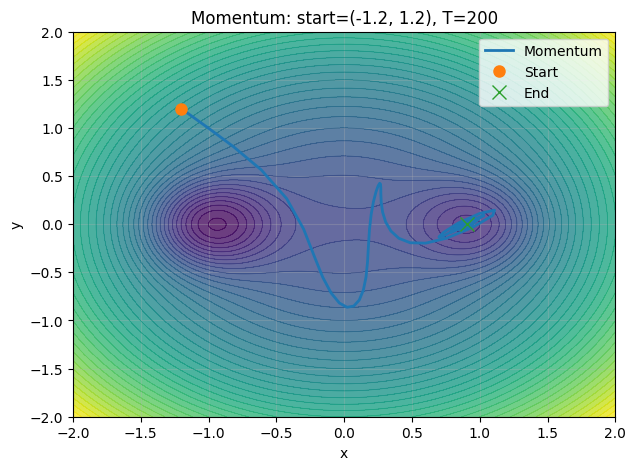

Momentum
Start: (-1.2, 1.2)
Steps: 200
Final point: (0.9053, -0.0000)
Final loss: -1.092732
Final well: Right well
----------------------------------------


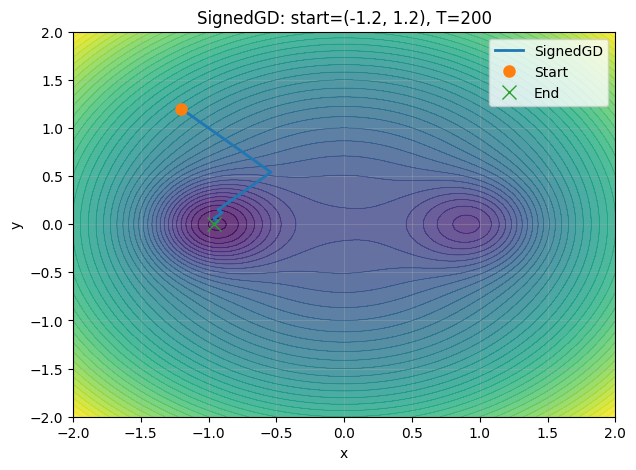

SignedGD
Start: (-1.2, 1.2)
Steps: 200
Final point: (-0.9600, -0.0000)
Final loss: -2.054496
Final well: Left well
----------------------------------------


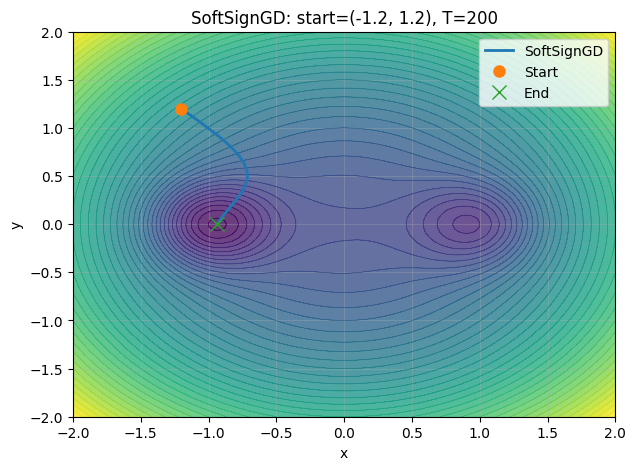

SoftSignGD
Start: (-1.2, 1.2)
Steps: 200
Final point: (-0.9363, 0.0000)
Final loss: -2.063090
Final well: Left well
----------------------------------------


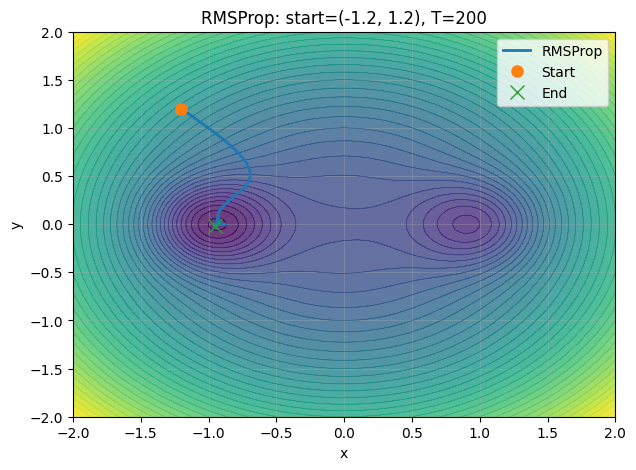

RMSProp
Start: (-1.2, 1.2)
Steps: 200
Final point: (-0.9510, -0.0150)
Final loss: -2.056247
Final well: Left well
----------------------------------------


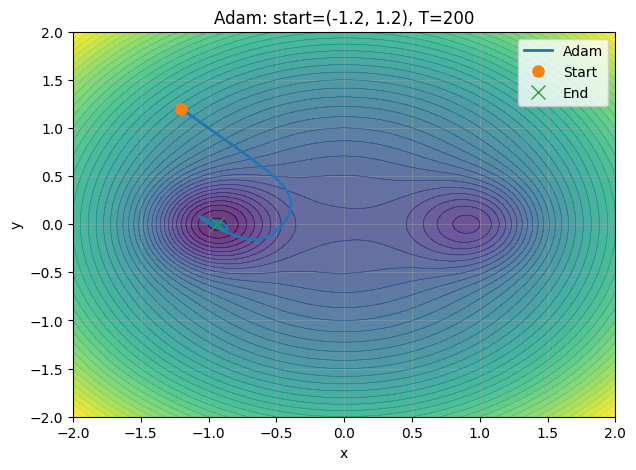

Adam
Start: (-1.2, 1.2)
Steps: 200
Final point: (-0.9356, -0.0000)
Final loss: -2.063082
Final well: Left well
----------------------------------------


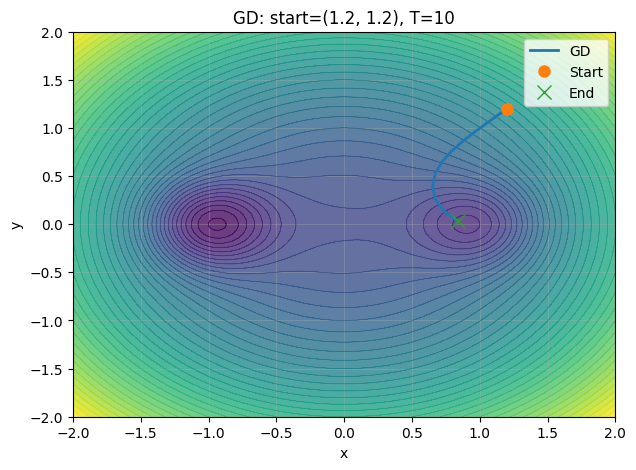

GD
Start: (1.2, 1.2)
Steps: 10
Final point: (0.8388, 0.0298)
Final loss: -1.044109
Final well: Right well
----------------------------------------


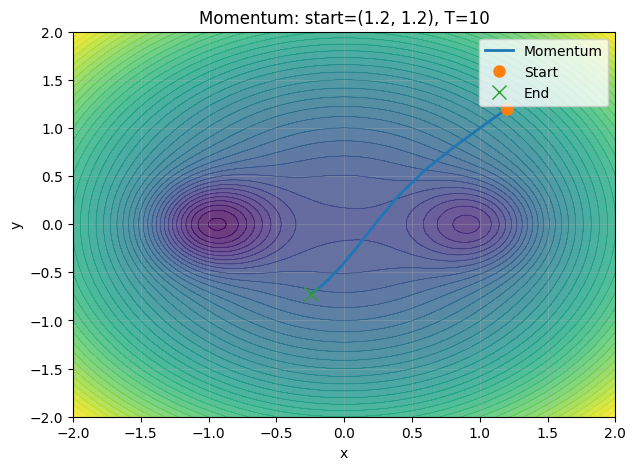

Momentum
Start: (1.2, 1.2)
Steps: 10
Final point: (-0.2410, -0.7228)
Final loss: 0.568164
Final well: Not converged
----------------------------------------


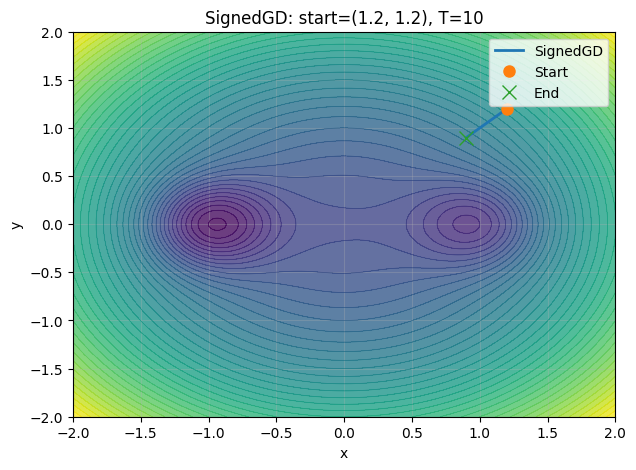

SignedGD
Start: (1.2, 1.2)
Steps: 10
Final point: (0.9000, 0.9000)
Final loss: 1.586855
Final well: Not converged
----------------------------------------


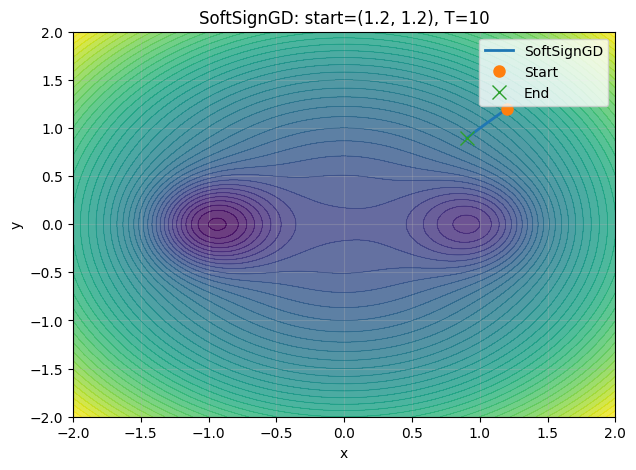

SoftSignGD
Start: (1.2, 1.2)
Steps: 10
Final point: (0.9025, 0.8928)
Final loss: 1.576135
Final well: Not converged
----------------------------------------


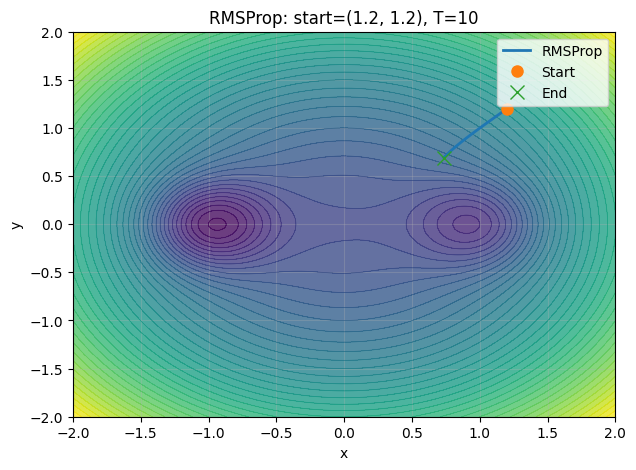

RMSProp
Start: (1.2, 1.2)
Steps: 10
Final point: (0.7344, 0.6912)
Final loss: 0.888240
Final well: Not converged
----------------------------------------


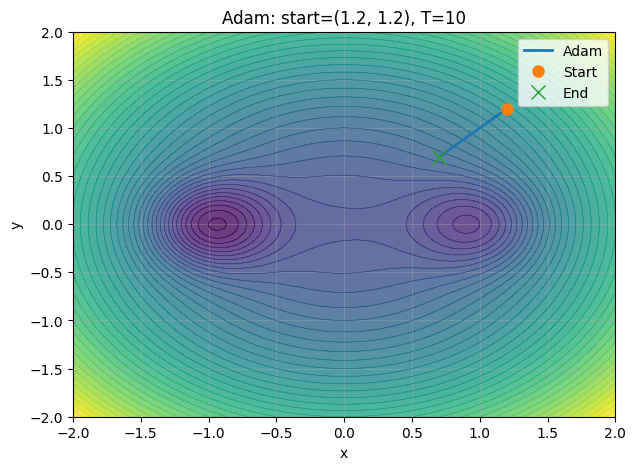

Adam
Start: (1.2, 1.2)
Steps: 10
Final point: (0.7025, 0.7004)
Final loss: 0.873454
Final well: Not converged
----------------------------------------


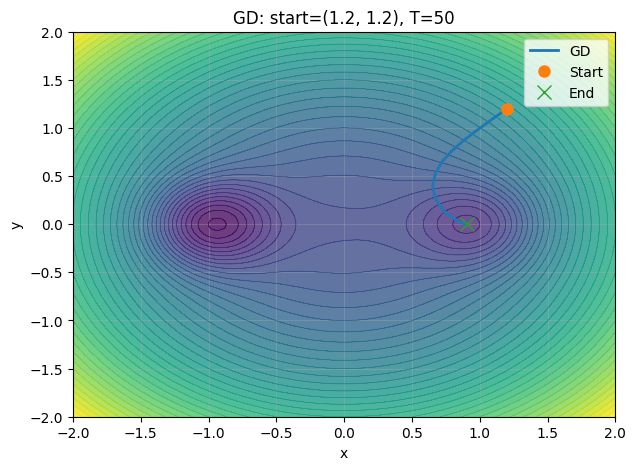

GD
Start: (1.2, 1.2)
Steps: 50
Final point: (0.9053, -0.0000)
Final loss: -1.092732
Final well: Right well
----------------------------------------


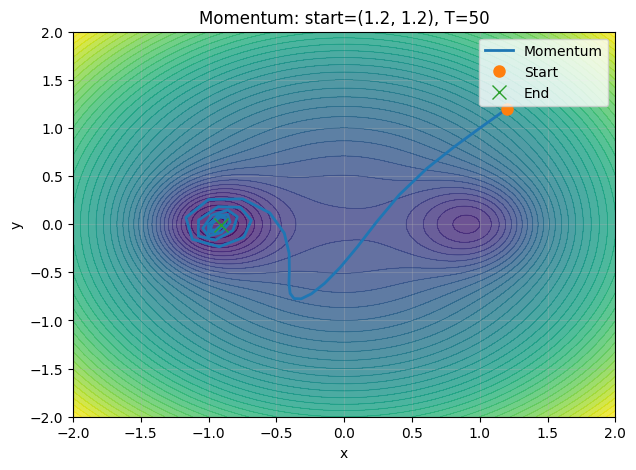

Momentum
Start: (1.2, 1.2)
Steps: 50
Final point: (-0.9064, -0.0089)
Final loss: -2.048663
Final well: Left well
----------------------------------------


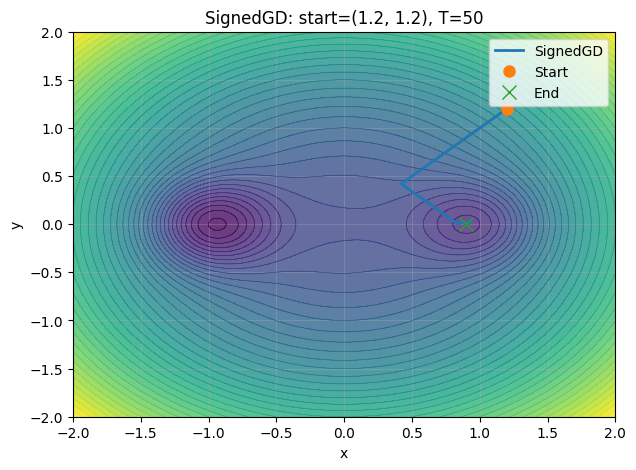

SignedGD
Start: (1.2, 1.2)
Steps: 50
Final point: (0.9000, -0.0000)
Final loss: -1.092459
Final well: Right well
----------------------------------------


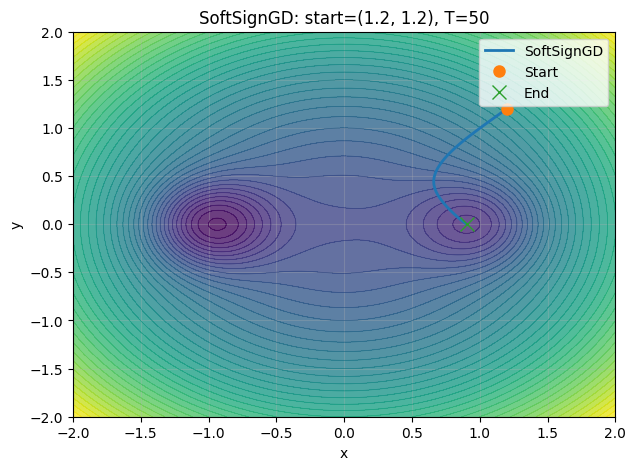

SoftSignGD
Start: (1.2, 1.2)
Steps: 50
Final point: (0.9052, 0.0000)
Final loss: -1.092732
Final well: Right well
----------------------------------------


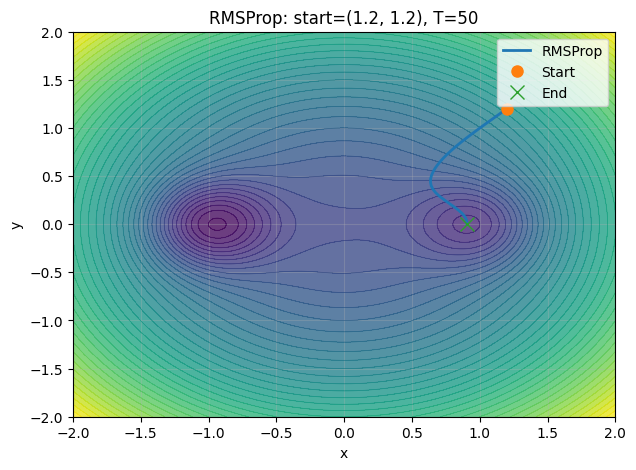

RMSProp
Start: (1.2, 1.2)
Steps: 50
Final point: (0.9053, 0.0000)
Final loss: -1.092732
Final well: Right well
----------------------------------------


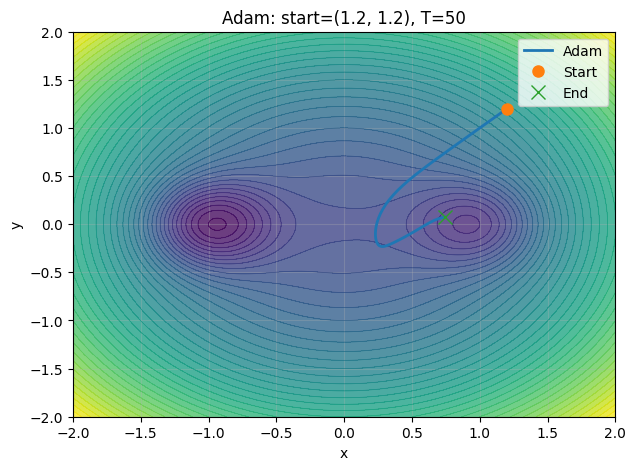

Adam
Start: (1.2, 1.2)
Steps: 50
Final point: (0.7444, 0.0743)
Final loss: -0.843642
Final well: Not converged
----------------------------------------


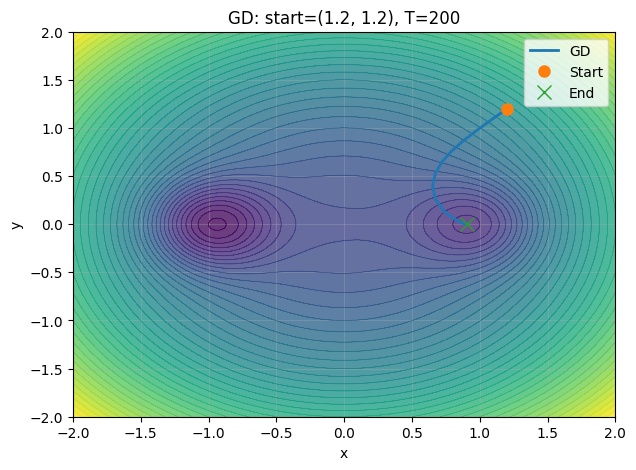

GD
Start: (1.2, 1.2)
Steps: 200
Final point: (0.9053, -0.0000)
Final loss: -1.092732
Final well: Right well
----------------------------------------


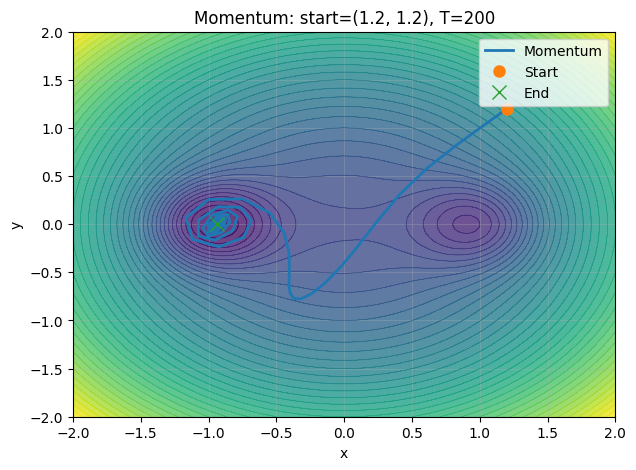

Momentum
Start: (1.2, 1.2)
Steps: 200
Final point: (-0.9363, -0.0000)
Final loss: -2.063090
Final well: Left well
----------------------------------------


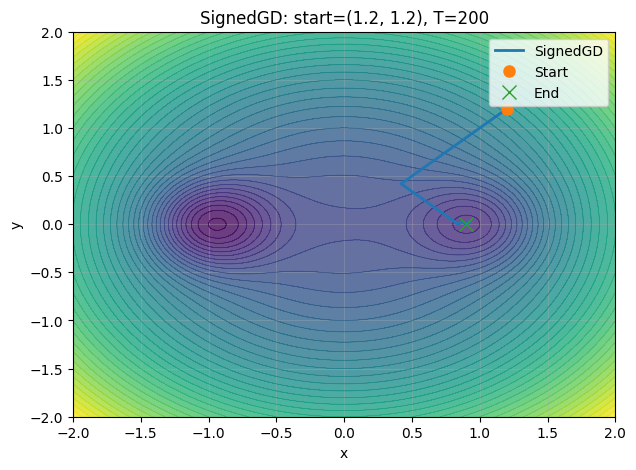

SignedGD
Start: (1.2, 1.2)
Steps: 200
Final point: (0.9000, -0.0000)
Final loss: -1.092459
Final well: Right well
----------------------------------------


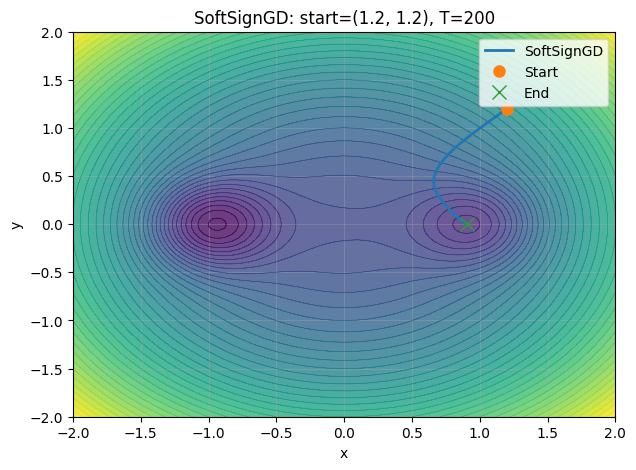

SoftSignGD
Start: (1.2, 1.2)
Steps: 200
Final point: (0.9053, 0.0000)
Final loss: -1.092732
Final well: Right well
----------------------------------------


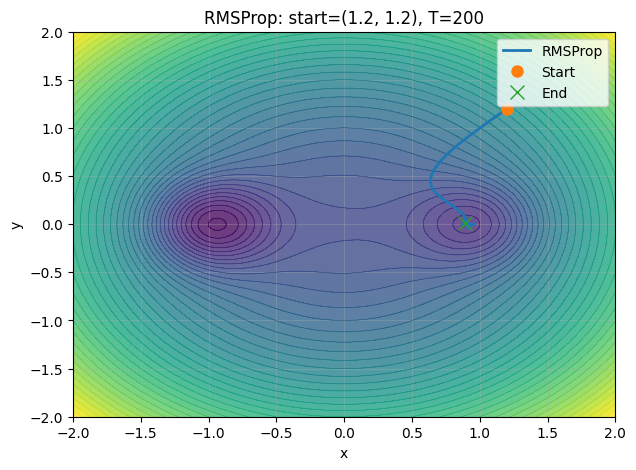

RMSProp
Start: (1.2, 1.2)
Steps: 200
Final point: (0.8900, 0.0153)
Final loss: -1.088050
Final well: Right well
----------------------------------------


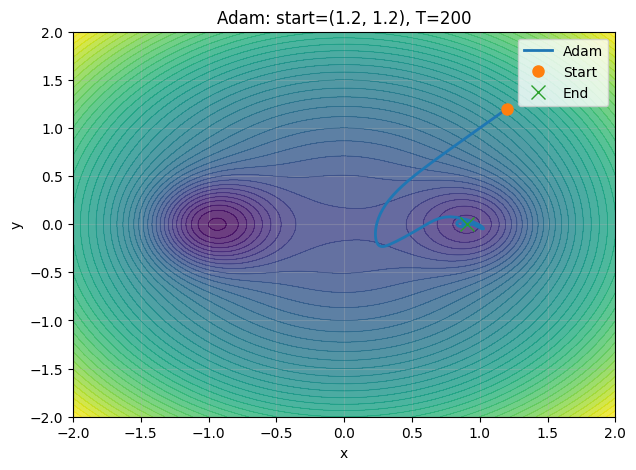

Adam
Start: (1.2, 1.2)
Steps: 200
Final point: (0.9043, 0.0021)
Final loss: -1.092676
Final well: Right well
----------------------------------------


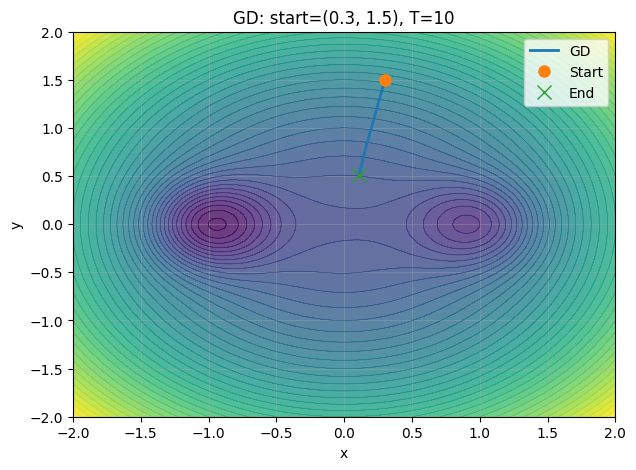

GD
Start: (0.3, 1.5)
Steps: 10
Final point: (0.1120, 0.5158)
Final loss: 0.266708
Final well: Not converged
----------------------------------------


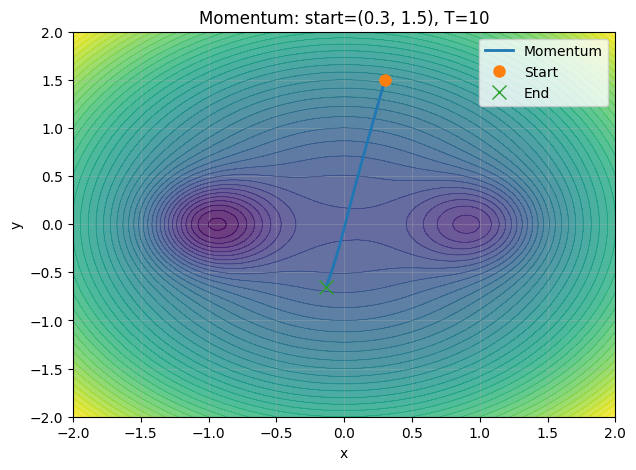

Momentum
Start: (0.3, 1.5)
Steps: 10
Final point: (-0.1326, -0.6476)
Final loss: 0.428038
Final well: Not converged
----------------------------------------


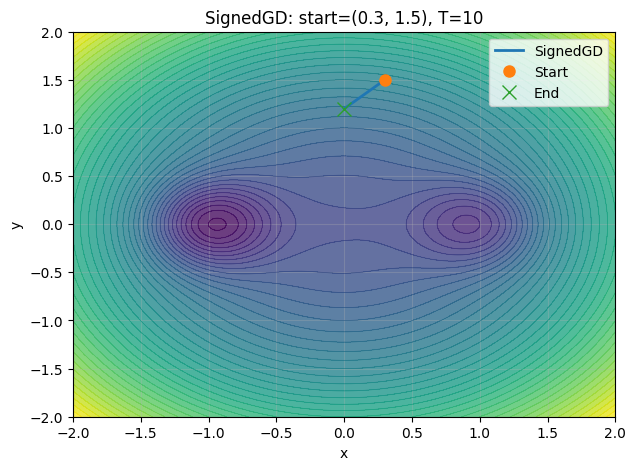

SignedGD
Start: (0.3, 1.5)
Steps: 10
Final point: (0.0000, 1.2000)
Final loss: 1.439975
Final well: Not converged
----------------------------------------


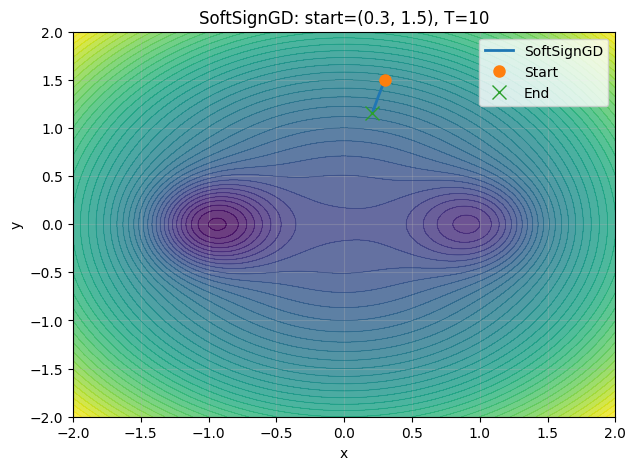

SoftSignGD
Start: (0.3, 1.5)
Steps: 10
Final point: (0.2073, 1.1517)
Final loss: 1.369365
Final well: Not converged
----------------------------------------


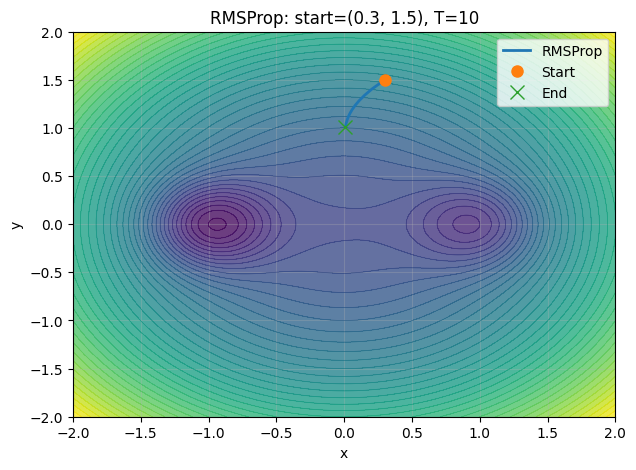

RMSProp
Start: (0.3, 1.5)
Steps: 10
Final point: (0.0096, 1.0142)
Final loss: 1.028519
Final well: Not converged
----------------------------------------


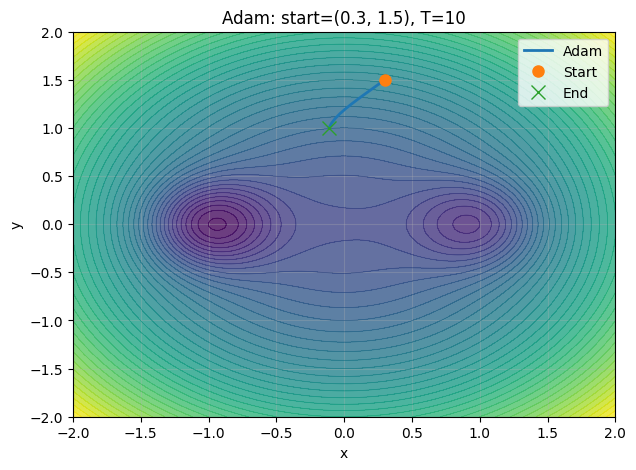

Adam
Start: (0.3, 1.5)
Steps: 10
Final point: (-0.1116, 1.0011)
Final loss: 1.014260
Final well: Not converged
----------------------------------------


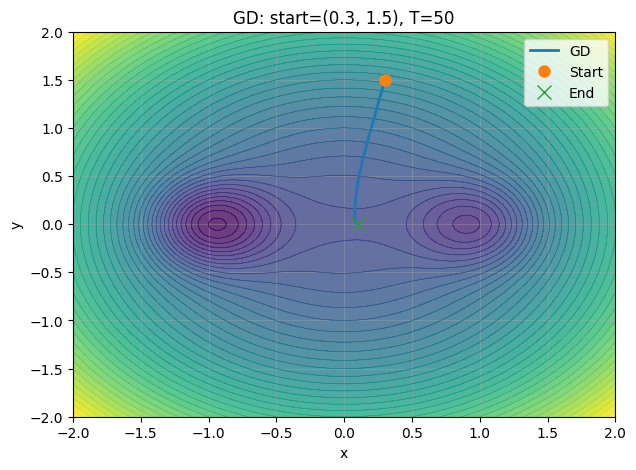

GD
Start: (0.3, 1.5)
Steps: 50
Final point: (0.1042, 0.0035)
Final loss: -0.032065
Final well: Not converged
----------------------------------------


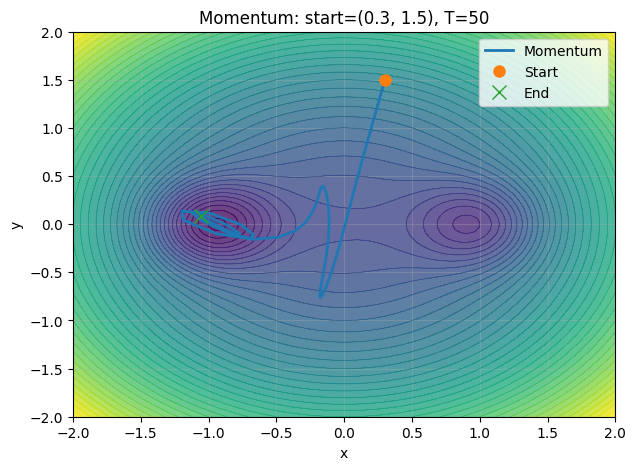

Momentum
Start: (0.3, 1.5)
Steps: 50
Final point: (-1.0546, 0.0871)
Final loss: -1.725944
Final well: Left well
----------------------------------------


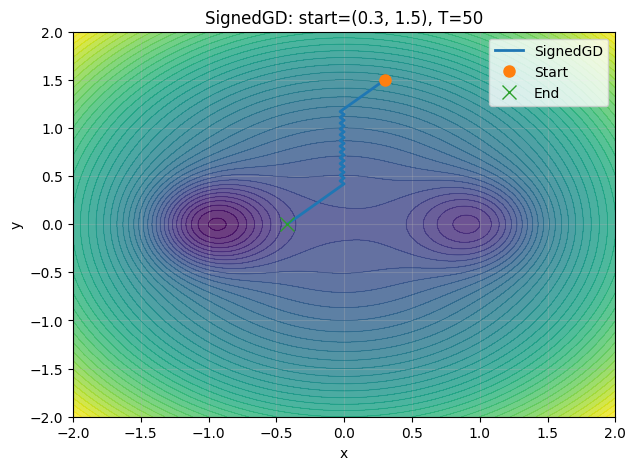

SignedGD
Start: (0.3, 1.5)
Steps: 50
Final point: (-0.4200, -0.0000)
Final loss: -0.381688
Final well: Not converged
----------------------------------------


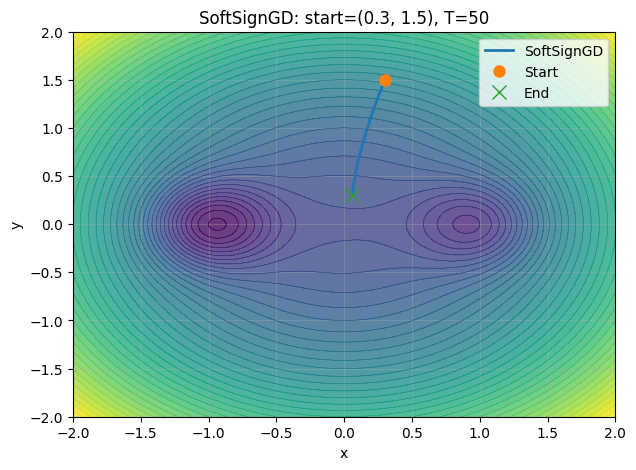

SoftSignGD
Start: (0.3, 1.5)
Steps: 50
Final point: (0.0604, 0.3035)
Final loss: 0.073639
Final well: Not converged
----------------------------------------


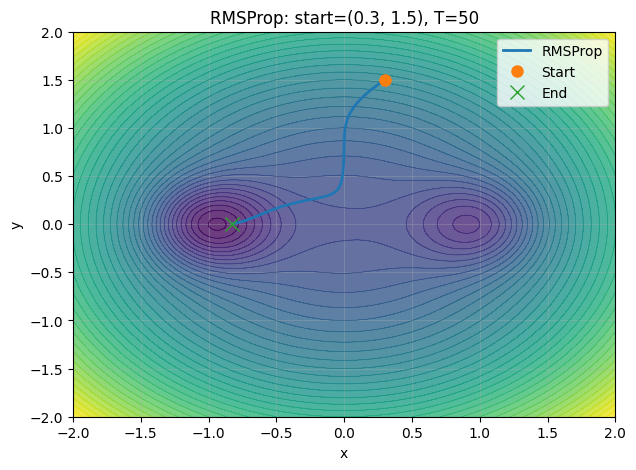

RMSProp
Start: (0.3, 1.5)
Steps: 50
Final point: (-0.8237, 0.0053)
Final loss: -1.889440
Final well: Left well
----------------------------------------


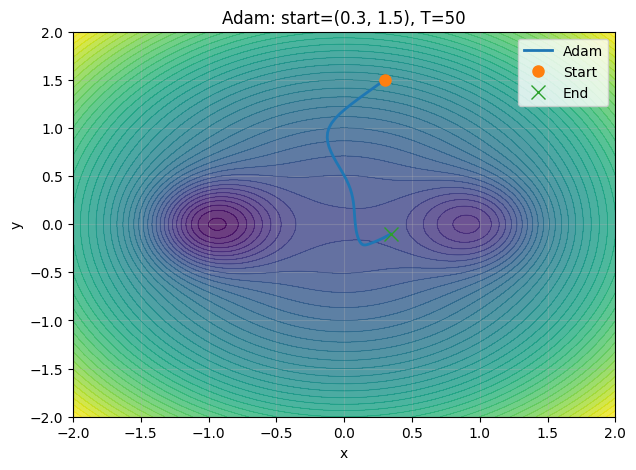

Adam
Start: (0.3, 1.5)
Steps: 50
Final point: (0.3444, -0.1008)
Final loss: -0.093221
Final well: Not converged
----------------------------------------


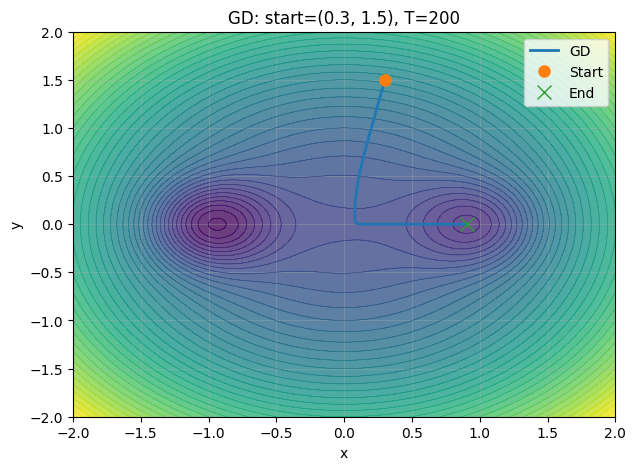

GD
Start: (0.3, 1.5)
Steps: 200
Final point: (0.9053, 0.0000)
Final loss: -1.092732
Final well: Right well
----------------------------------------


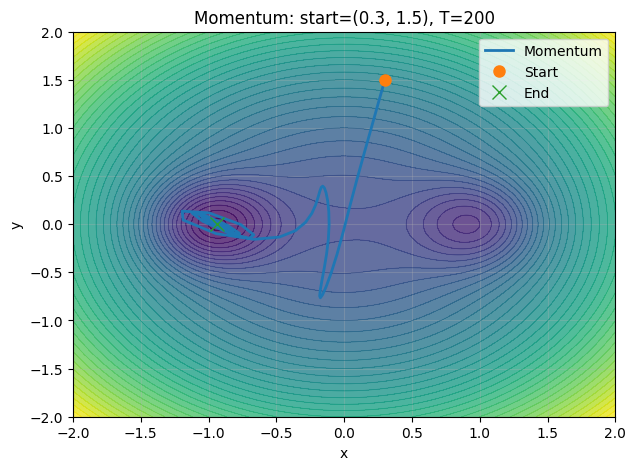

Momentum
Start: (0.3, 1.5)
Steps: 200
Final point: (-0.9363, 0.0000)
Final loss: -2.063090
Final well: Left well
----------------------------------------


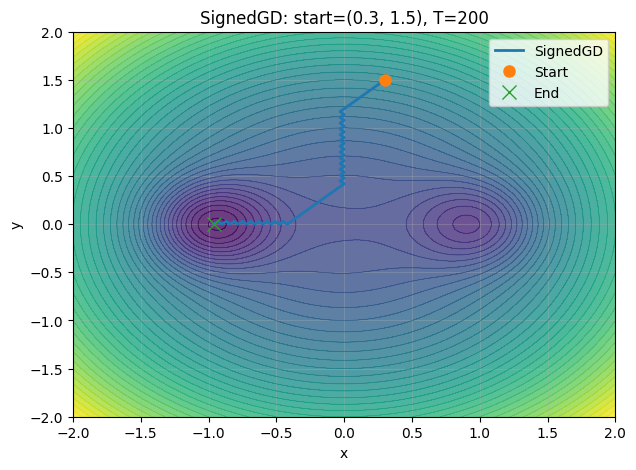

SignedGD
Start: (0.3, 1.5)
Steps: 200
Final point: (-0.9600, -0.0000)
Final loss: -2.054496
Final well: Left well
----------------------------------------


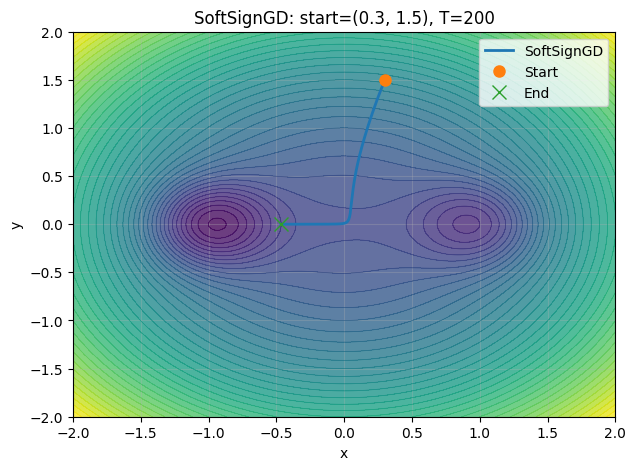

SoftSignGD
Start: (0.3, 1.5)
Steps: 200
Final point: (-0.4673, 0.0001)
Final loss: -0.507564
Final well: Not converged
----------------------------------------


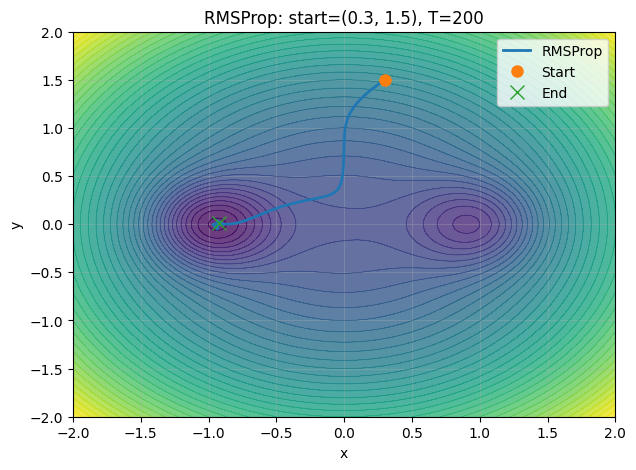

RMSProp
Start: (0.3, 1.5)
Steps: 200
Final point: (-0.9210, 0.0150)
Final loss: -2.056090
Final well: Left well
----------------------------------------


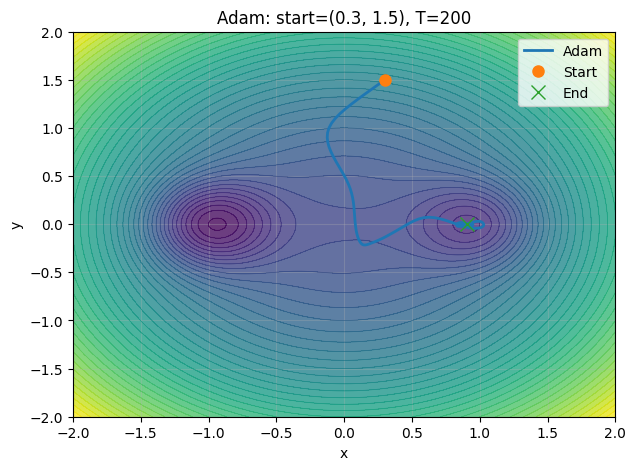

Adam
Start: (0.3, 1.5)
Steps: 200
Final point: (0.9038, 0.0008)
Final loss: -1.092704
Final well: Right well
----------------------------------------


In [9]:
for start in STARTS:
    for steps in BUDGETS:
        for name, optimizer in optimizers.items():

            traj, losses = optimizer(
                start[0],
                start[1],
                steps
            )

            # Plot trajectory
            plot_trajectory(
                name,
                traj,
                start,
                steps
            )

            # Final information
            final_x = traj[-1, 0]
            final_y = traj[-1, 1]
            final_loss = losses[-1]

            # Determine which well
            well = classify_well(final_x, final_y)

            print(f"{name}")
            print(f"Start: {start}")
            print(f"Steps: {steps}")
            print(f"Final point: ({final_x:.4f}, {final_y:.4f})")
            print(f"Final loss: {final_loss:.6f}")
            print(f"Final well: {well}")
            print("-" * 40)

### Qualitative Observations


*   Increasing the step budget generally moved the optimizers closer to a local minimum, as shown by lower final objective values at larger T.
*   The final solution depended strongly on initialization. For example, GD converged to the left well from (-1.2, 1.2) but to the right well from (1.2, 1.2).
*   GD tended to remain in the basin associated with its starting side.
*   Momentum sometimes crossed between the two wells because its velocity accumulates information from previous updates.
*   SignGD used nearly constant-sized coordinate updates because it only uses the sign of the gradient.
*   SoftSignGD produced gradually varying updates because its update magnitude still depends on the gradient.
*   RMSProp and Adam used adaptive step scaling, causing their effective update sizes to change throughout optimization.
*   Depending on the initialization and step budget, different optimizers converged to either the deeper left well or the shallower right well.

## Hyperparameter exploration and comparison


In [10]:
# -------------------------------------
# Hyperparameter exploration settings
# -------------------------------------

EXPLORATION_BUDGETS = [50, 200]

PARAM_GRIDS = {
    "GD": [
        {"lr": lr}
        for lr in [0.01, 0.03, 0.05, 0.10]
    ],

    "Momentum": [
        {"lr": lr, "mu": mu}
        for lr in [0.01, 0.03, 0.05]
        for mu in [0.5, 0.9, 0.95]
    ],

    "SignedGD": [
        {"lr": lr}
        for lr in [0.01, 0.03, 0.05, 0.10]
    ],

    "SoftSignGD": [
        {"lr": lr, "tau": tau}
        for lr in [0.03, 0.10, 0.20]
        for tau in [1.0, 5.0, 10.0]
    ],

    "RMSProp": [
        {"lr": lr, "beta": beta, "eps": 1e-8}
        for lr in [0.01, 0.03, 0.05]
        for beta in [0.9, 0.99]
    ],

    "Adam": [
        {
            "lr": lr,
            "b1": b1,
            "b2": b2,
            "eps": 1e-8
        }
        for lr in [0.01, 0.05, 0.10]
        for b1 in [0.8, 0.9]
        for b2 in [0.9, 0.999]
    ]
}

In [11]:
RUNNERS = {
    "GD": run_gd,
    "Momentum": run_momentum,
    "SignedGD": run_sign_gd,
    "SoftSignGD": run_softsign_gd,
    "RMSProp": run_rmsprop,
    "Adam": run_adam
}

In [12]:
STARTS = [
    (-1.2, 1.2),
    (1.2, 1.2),
    (0.3, 1.5)
]

In [13]:
import pandas as pd

experiment_results = []

for optimizer_name, param_list in PARAM_GRIDS.items():

    for params in param_list:

        for start in STARTS:

            for steps in EXPLORATION_BUDGETS:

                traj, losses = RUNNERS[optimizer_name](
                    start[0],
                    start[1],
                    steps,
                    **params
                )

                final_x = traj[-1, 0]
                final_y = traj[-1, 1]
                final_loss = losses[-1]

                # Which well region did it reach?
                well = classify_well(final_x, final_y)

                experiment_results.append({
                    "Optimizer": optimizer_name,
                    "Start": start,
                    "Steps": steps,
                    "Parameters": tuple(sorted(params.items())),
                    "Final x": final_x,
                    "Final y": final_y,
                    "Final Objective": final_loss,
                    "Well": well
                })


results_df = pd.DataFrame(experiment_results)

results_df.head()

,Optimizer,Start,Steps,Parameters,Final x,Final y,Final Objective,Well
0,GD,"(-1.2, 1.2)",50,"((lr, 0.01),)",-0.935702,6.346035e-04,-2.063079,Left well
1,GD,"(-1.2, 1.2)",200,"((lr, 0.01),)",-0.936301,1.793653e-28,-2.063090,Left well
2,GD,"(1.2, 1.2)",50,"((lr, 0.01),)",0.869819,3.228366e-02,-1.070333,Right well
3,GD,"(1.2, 1.2)",200,"((lr, 0.01),)",0.905318,1.184002e-17,-1.092732,Right well
4,GD,"(0.3, 1.5)",50,"((lr, 0.01),)",0.116738,5.389808e-01,0.293288,Not converged


In [14]:
summary_df = (
    results_df
    .groupby(
        ["Optimizer", "Steps", "Parameters"],
        as_index=False
    )
    .agg(
        Average_Final_Objective=("Final Objective", "mean"),

        Left_Well_Count=(
            "Well",
            lambda x: (x == "Left well").sum()
        ),

        Right_Well_Count=(
            "Well",
            lambda x: (x == "Right well").sum()
        ),

        Not_Converged_Count=(
            "Well",
            lambda x: (x == "Not converged").sum()
        )
    )
)

summary_df

,Optimizer,Steps,Parameters,Average_Final_Objective,Left_Well_Count,Right_Well_Count,Not_Converged_Count
0,Adam,50,"((b1, 0.8), (b2, 0.9), (eps, 1e-08), (lr, 0.01))",0.918550,0,0,3
1,Adam,50,"((b1, 0.8), (b2, 0.9), (eps, 1e-08), (lr, 0.05))",-1.693982,2,1,0
2,Adam,50,"((b1, 0.8), (b2, 0.9), (eps, 1e-08), (lr, 0.1))",-1.738841,2,1,0
3,Adam,50,"((b1, 0.8), (b2, 0.999), (eps, 1e-08), (lr, 0....",0.960386,0,0,3
4,Adam,50,"((b1, 0.8), (b2, 0.999), (eps, 1e-08), (lr, 0....",-1.653268,2,1,0
...,...,...,...,...,...,...,...
83,SoftSignGD,200,"((lr, 0.1), (tau, 5.0))",-1.221129,1,1,1
84,SoftSignGD,200,"((lr, 0.1), (tau, 10.0))",-1.062221,1,1,1
85,SoftSignGD,200,"((lr, 0.2), (tau, 1.0))",-1.637829,2,1,0
86,SoftSignGD,200,"((lr, 0.2), (tau, 5.0))",-1.739638,2,1,0


In [15]:
# -------------------------------------
# Best hyperparameters for each optimizer
# -------------------------------------

FIXED_STEPS = 200

fixed_summary = summary_df[
    summary_df["Steps"] == FIXED_STEPS
].copy()

best_indices = (
    fixed_summary
    .groupby("Optimizer")["Average_Final_Objective"]
    .idxmin()
)

best_settings_df = (
    fixed_summary
    .loc[best_indices]
    .sort_values("Average_Final_Objective")
    .reset_index(drop=True)
)

best_settings_df

,Optimizer,Steps,Parameters,Average_Final_Objective,Left_Well_Count,Right_Well_Count,Not_Converged_Count
0,Adam,200,"((b1, 0.9), (b2, 0.999), (eps, 1e-08), (lr, 0.1))",-2.063090,3,0,0
1,Momentum,200,"((lr, 0.05), (mu, 0.9))",-2.063090,3,0,0
2,RMSProp,200,"((beta, 0.99), (eps, 1e-08), (lr, 0.01))",-1.739638,2,1,0
3,SoftSignGD,200,"((lr, 0.03), (tau, 1.0))",-1.739638,2,1,0
4,SignedGD,200,"((lr, 0.01),)",-1.739408,2,1,0
5,GD,200,"((lr, 0.03),)",-1.416185,1,2,0


In [16]:
print("BEST SETTINGS FOR EACH OPTIMIZER")
print("=" * 70)

for _, row in best_settings_df.iterrows():

    print(f"\nOptimizer: {row['Optimizer']}")
    print(f"Best parameters: {dict(row['Parameters'])}")
    print(
        f"Average final objective: "
        f"{row['Average_Final_Objective']:.6f}"
    )
    print(f"Left well: {row['Left_Well_Count']}/3")
    print(f"Right well: {row['Right_Well_Count']}/3")

BEST SETTINGS FOR EACH OPTIMIZER

Optimizer: Adam
Best parameters: {'b1': 0.9, 'b2': 0.999, 'eps': 1e-08, 'lr': 0.1}
Average final objective: -2.063090
Left well: 3/3
Right well: 0/3

Optimizer: Momentum
Best parameters: {'lr': 0.05, 'mu': 0.9}
Average final objective: -2.063090
Left well: 3/3
Right well: 0/3

Optimizer: RMSProp
Best parameters: {'beta': 0.99, 'eps': 1e-08, 'lr': 0.01}
Average final objective: -1.739638
Left well: 2/3
Right well: 1/3

Optimizer: SoftSignGD
Best parameters: {'lr': 0.03, 'tau': 1.0}
Average final objective: -1.739638
Left well: 2/3
Right well: 1/3

Optimizer: SignedGD
Best parameters: {'lr': 0.01}
Average final objective: -1.739408
Left well: 2/3
Right well: 1/3

Optimizer: GD
Best parameters: {'lr': 0.03}
Average final objective: -1.416185
Left well: 1/3
Right well: 2/3


In [17]:
best_average = best_settings_df[
    "Average_Final_Objective"
].min()

winners = best_settings_df[
    np.isclose(
        best_settings_df["Average_Final_Objective"],
        best_average,
        atol=1e-6
    )
]

print("\nOVERALL WINNER(S)")
print("=" * 70)

for _, row in winners.iterrows():
    print(
        f"{row['Optimizer']} "
        f"with average final objective = "
        f"{row['Average_Final_Objective']:.6f}"
    )


OVERALL WINNER(S)
Adam with average final objective = -2.063090
Momentum with average final objective = -2.063090


For each optimizer, I tested multiple hyperparameter settings using the three specified starting points and step budgets of 50 and 200. At the fixed comparison budget of T = 200, I selected the setting that produced the lowest average final objective across the three initializations. Since the objective is being minimized, lower average objective values indicate better performance.

At T = 200, Adam and Momentum achieved the lowest average final objective across the three initializations. Both also reached the left well from all three starting points. Momentum benefits from accumulated velocity, which can help it move across the nonconvex landscape rather than remaining near the closest local minimum. Adam combines momentum with adaptive step scaling, allowing it to make effective progress across different gradient magnitudes. GD was more sensitive to initialization and reached the right well for more of the tested starting points.